In [12]:
def allInOne(path, i, rPathsArr, rOneArr, rMultArr, avgHopsPathsArr, avgHopsOneArr, avgHopsMultArr, avgHopsSPArr, printRes=True):

    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt

    def filterArraysToShortest(arr1, arr1Pos, arr2, arr2Pos):
        both_pos = np.logical_and(arr1Pos, arr2Pos)
        arr1Filt = arr1[both_pos] 
        arr2Filt = arr2[both_pos] 
    
        return arr1Filt, arr2Filt
    
    
    df = pd.read_csv(path)
    if printRes:
        display(df.head(5))
    
    reps = df['rep'].to_numpy()
    hopsRanked = df['hopsRanked'].to_numpy()
    hopsUnranked = df['hopsUnranked'].to_numpy()
    hopsRankedOne = df['hopsRankedOne'].to_numpy()
    hopsPath = df['hopsPath'].to_numpy()
    spLength = df['spLength'].to_numpy()

    hopsRankedPositive = hopsRanked > -1
    hopsUnrankedPositive = hopsUnranked > -1
    hopsRankedOnePositive = hopsRankedOne > -1
    hopsPathPositive = hopsPath > -1
    spLengthPositive = spLength > -1
    
    
    total = len(df.index)

    successesRanked = np.count_nonzero(hopsRanked > -1)
    successesRankedOne = np.count_nonzero(hopsRankedOne > -1)
    successesUnranked = np.count_nonzero(hopsUnranked > -1)
    successesPath = np.count_nonzero(hopsPath > -1)

    avgHopsPath = np.mean(hopsPath[hopsPathPositive])
    
    hopsPathFiltered,hopsRankedFiltered = filterArraysToShortest(hopsPath, hopsPathPositive, hopsRanked, hopsRankedPositive)
    avgHopsMult = np.mean(hopsRankedFiltered)
    avgHopsMultFull = np.mean(hopsRanked[hopsRankedPositive])
    
    if printRes:
        print("avg where both found D:", avgHopsMult)
        print("avg full:", avgHopsMultFull)
    
    hopsPathFiltered,hopsRankedOneFiltered = filterArraysToShortest(hopsPath, hopsPathPositive, hopsRankedOne, hopsRankedOnePositive)   
    avgHopsOne = np.mean(hopsRankedOneFiltered)
    
    avgSpLength = np.mean(spLength[spLengthPositive])

    percentPaths = (successesPath / total) * 100
    percentOne = (successesRankedOne / total) * 100
    percentRanked = (successesRanked / total) * 100
    
    if printRes:
        print("Resilience Paths: {}%".format(percentPaths))
        print("Resilience One Tree: {}%".format(percentOne))
        print("Resilience Trees: {}%".format(percentRanked))
        #print("Resilience Unranked: {}%".format((successesUnranked / total) * 100))

  
    hopsPathFiltered,hopsRankedFiltered = filterArraysToShortest(hopsPath, hopsPathPositive, hopsRanked, hopsRankedPositive)   
    


    diff = np.subtract(hopsPathFiltered,hopsRankedFiltered)
    if printRes:
        plt.scatter(np.arange(len(hopsPathFiltered)), diff, color="blue", s=1.5)
        plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)
    
    if printRes:
        print("Trees beat paths in {} runs".format(higherZero))
        print("Paths beat trees in {} runs".format(lowerZero))
        print("Both performed equally good in {} runs".format(equalZero))
    

    hopsPathFiltered,hopsRankedOneFiltered = filterArraysToShortest(hopsPath, hopsPathPositive, hopsRankedOne, hopsRankedOnePositive)   

    diff = np.subtract(hopsPathFiltered,hopsRankedOneFiltered)
    if printRes:
        plt.scatter(np.arange(len(hopsPathFiltered)), diff, color="blue", s=1.5);
        plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)
    
    if printRes:
        print("One Tree beat paths in {} runs".format(higherZero))
        print("Paths beat one tree in {} runs".format(lowerZero))
        print("Both performed equally good in {} runs".format(equalZero))




    hopsRankedOneFiltered,hopsRankedFiltered = filterArraysToShortest(hopsRankedOne, hopsRankedOnePositive, hopsRanked, hopsRankedPositive)   

    diff = np.subtract(hopsRankedOneFiltered,hopsRankedFiltered)
    
    if printRes:
        plt.scatter(np.arange(len(hopsRankedFiltered)), diff, color="blue", s=1.5);
        plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)

    if printRes:
        print("Multiple Trees beat One Tree in {} runs".format(higherZero))
        print("One Tree beat  multiple trees in {} runs".format(lowerZero))
        print("Both performed equally good in {} runs".format(equalZero))




    hopsUnrankedFiltered,hopsRankedFiltered = filterArraysToShortest(hopsUnranked, hopsUnrankedPositive, hopsRanked, hopsRankedPositive)   

    diff = np.subtract(hopsUnrankedFiltered,hopsRankedFiltered)
    if printRes:
        plt.scatter(np.arange(len(hopsRankedFiltered)), diff, color="blue", s=1.5);
        plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)

    if printRes:
        print("Ranked Trees beat Unranked Tree in {} runs".format(higherZero))
        print("Unranked Tree beat ranked trees in {} runs".format(lowerZero))
        print("Both performed equally good in {} runs".format(equalZero))
    
    rPathsArr[i] = percentPaths
    rOneArr[i] = percentOne
    rMultArr[i] = percentRanked
    avgHopsPathsArr[i] = avgHopsPath
    avgHopsOneArr[i] = avgHopsOne
    avgHopsMultArr[i] = avgHopsMult
    avgHopsSPArr[i] = avgSpLength
    
    return 

In [13]:
def plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP):
    import matplotlib.pyplot as plt
    import numpy as np
    import matplotlib.patches as mpatches
    
    
    edp_patch = mpatches.Patch(color='skyblue', label='EDPs')
    onetree_patch = mpatches.Patch(color='darkred', label='One Tree')
    multtrees_patch = mpatches.Patch(color='lightgreen', label='Multiple Trees')
    both_patch = mpatches.Patch(color='violet', label='EDPs + One Tree')
    
    
    plt.plot(xVals, rPaths, marker='o', markerfacecolor='blue', markersize=6, color='skyblue', linewidth=4)
    plt.plot(xVals, rOne, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=4)
    plt.plot(xVals, rMult, marker='o', markerfacecolor='green', markersize=6, color='lightgreen', linewidth=4)
    plt.title('Resilience - Failure Rate')
    plt.xlabel('Failure Rate')
    plt.ylabel('Resilience')
 
    plt.legend(handles=[edp_patch, onetree_patch, multtrees_patch])
    plt.show()
    
    
    
    plt.plot(xVals, avgHopsPaths, marker='o', markerfacecolor='purple', markersize=6, color='violet', linewidth=4)
    #plt.plot(xVals, avgHopsPaths, marker='o', markerfacecolor='blue', markersize=6, color='skyblue', linewidth=4)
    #plt.plot(xVals, avgHopsOne, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=4)
    plt.plot(xVals, avgHopsMult, marker='o', markerfacecolor='green', markersize=6, color='lightgreen', linewidth=4)
    plt.title('Avg. Hops - Failure Rate')
    plt.xlabel('Failure Rate')
    plt.ylabel('Average Hops')
    
    plt.legend(handles=[both_patch, multtrees_patch])
    plt.show()
    
    

    percentAvgsOneToPaths = []
    percentAvgsMultToPaths = []

    def getIncrease(val1, val2):
        return (abs(val2 - val1) / val1) * 100.0

    for i in range(len(avgHopsPaths)):
        percentAvgsOneToPaths.append(getIncrease(avgHopsPaths[i], avgHopsOne[i]))
        percentAvgsMultToPaths.append(getIncrease(avgHopsPaths[i], avgHopsMult[i]))
        
        
    plt.plot(xVals, percentAvgsOneToPaths, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=4)
    plt.plot(xVals, percentAvgsMultToPaths, marker='o', markerfacecolor='green', markersize=6, color='lightgreen', linewidth=4)

    plt.title('Percent Increase in Hops - Failure Rate')
    plt.xlabel('Failure Rate')
    plt.ylabel('Percent difference to BLUE')
    plt.show()
    
    
    percentAvgsOneToSP = []
    percentAvgsMultToSP = []
    percentAvgsPathsToSP = []

    for i in range(len(avgHopsPaths)):
        percentAvgsOneToSP.append(getIncrease(avgHopsSP[i], avgHopsOne[i]))

        percentAvgsMultToSP.append(getIncrease(avgHopsSP[i], avgHopsMult[i]))
        percentAvgsPathsToSP.append(getIncrease(avgHopsSP[i], avgHopsPaths[i]))
        
        
    plt.plot(xVals, percentAvgsOneToSP, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=4)
    plt.plot(xVals, percentAvgsMultToSP, marker='o', markerfacecolor='green', markersize=6, color='lightgreen', linewidth=4)
    plt.plot(xVals, percentAvgsPathsToSP, marker='o', markerfacecolor='blue', markersize=6, color='skyblue', linewidth=4)

    plt.title('Percent Increase to SP - Failure Rate')
    plt.xlabel('Failure Rate')
    plt.ylabel('Percent difference to Shortest Path')
    plt.show()   

In [14]:
def plotEvalAx(ax, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP):
    
    import matplotlib.pyplot as plt
    import numpy as np
    import matplotlib.patches as mpatches
    
    linewidth = 2 
    ax1, ax2, index = ax
    
    xVals = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
    
    edp_patch = mpatches.Patch(color='skyblue', label='EDPs')
    onetree_patch = mpatches.Patch(color='darkred', label='One Tree')
    multtrees_patch = mpatches.Patch(color='lightgreen', label='Multiple Trees')
    both_patch = mpatches.Patch(color='violet', label='EDPs + One Tree')
    
    
    ax1[index].plot(xVals, rPaths, marker='o', markerfacecolor='blue', markersize=6, color='skyblue', linewidth=linewidth)
    ax1[index].plot(xVals, rOne, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=linewidth)
    ax1[index].plot(xVals, rMult, marker='o', markerfacecolor='green', markersize=6, color='lightgreen', linewidth=linewidth)
    #ax.title('Resilience - Failure Rate')
    #ax.xlabel('Failure Rate')
    #ax.ylabel('Resilience')
 
    if index == 0:
        ax1[index].legend(handles=[edp_patch, onetree_patch, multtrees_patch])
    #ax.show()
    
    
    
    ax2[index].plot(xVals, avgHopsPaths, marker='o', markerfacecolor='purple', markersize=6, color='violet', linewidth=linewidth)
    #ax.plot(xVals, avgHopsPaths, marker='o', markerfacecolor='blue', markersize=6, color='skyblue', linewidth=linewidth)
    #ax.plot(xVals, avgHopsOne, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=linewidth)
    ax2[index].plot(xVals, avgHopsMult, marker='o', markerfacecolor='green', markersize=6, color='lightgreen', linewidth=linewidth)
    #ax.title('Avg. Hops - Failure Rate')
    #ax.xlabel('Failure Rate')
    #ax.ylabel('Average Hops')
    
    if index == 0:
        ax2[index].legend(handles=[both_patch, multtrees_patch])
    #ax.show()
    
    


In [15]:
def plotEvalAx2(xVals, ax, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, markersize=3, alpha=1):
    
    import matplotlib.pyplot as plt
    import numpy as np
    import matplotlib.patches as mpatches
    
    linewidth = 2 
    ax1, ax2, index = ax
    
    edp_patch = mpatches.Patch(color='skyblue', label='EDPs')
    onetree_patch = mpatches.Patch(color='darkred', label='One Tree')
    multtrees_patch = mpatches.Patch(color='lightgreen', label='Multiple Trees')
    both_patch = mpatches.Patch(color='violet', label='EDPs + One Tree')
    
    ax1[index].plot(xVals, rPaths, marker='o', markerfacecolor='blue', markersize=markersize, color='skyblue', linewidth=linewidth, alpha=alpha)
    ax1[index].plot(xVals, rOne, marker='x', markerfacecolor='red', markersize=markersize, color='darkred', linewidth=linewidth, alpha=alpha)
    ax1[index].plot(xVals, rMult, marker='o', markerfacecolor='green', markersize=markersize, color='lightgreen', linewidth=linewidth, alpha=alpha)
    #ax.title('Resilience - Failure Rate')
    #ax.xlabel('Failure Rate')
    #ax.ylabel('Resilience')
 
    if index == 0:
        ax1[index].legend(handles=[edp_patch, onetree_patch, multtrees_patch])
    #ax.show()
    
    
    
    ax2[index].plot(xVals, avgHopsPaths, marker='o', markerfacecolor='purple', markersize=markersize, color='violet', linewidth=linewidth, alpha=1)
    #ax.plot(xVals, avgHopsPaths, marker='o', markerfacecolor='blue', markersize=6, color='skyblue', linewidth=linewidth)
    #ax.plot(xVals, avgHopsOne, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=linewidth)
    ax2[index].plot(xVals, avgHopsMult, marker='o', markerfacecolor='green', markersize=markersize, color='lightgreen', linewidth=linewidth, alpha=1)
    #ax.title('Avg. Hops - Failure Rate')
    #ax.xlabel('Failure Rate')
    #ax.ylabel('Average Hops')
    
    if index == 0:
        ax2[index].legend(handles=[both_patch, multtrees_patch])
    #ax.show()
    

In [16]:
#path_base = 'CSVs/n25-clustered/'
path_base = '../../output/Paper_CSVs/n25-random/'

In [17]:
import numpy as np
def printHopPercent(avgHopsPaths, avgHopsOne, avgHopsMult):
    increaseArrMult = np.array(avgHopsMult) / np.array(avgHopsPaths)
    increaseArrOne = np.array(avgHopsOne) / np.array(avgHopsPaths)
    print("percent increase mult to edp:", increaseArrMult)
    print("percent increase one to edp:", increaseArrOne)

    print("avg increase mult to edp:", np.mean(increaseArrMult))
    print("avg increase one to edp:", np.mean(increaseArrOne))

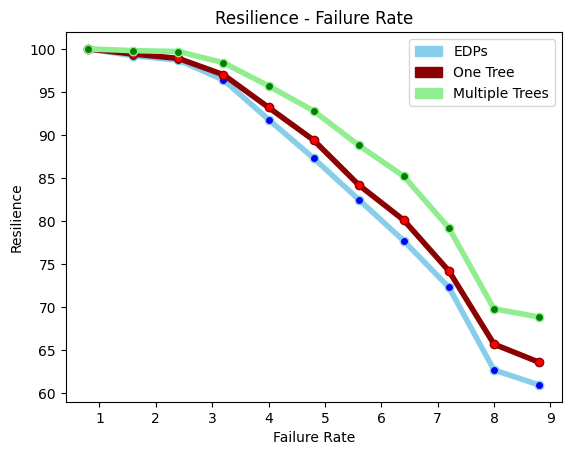

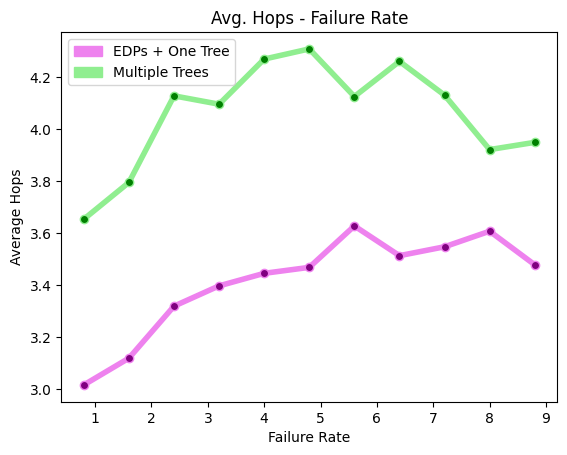

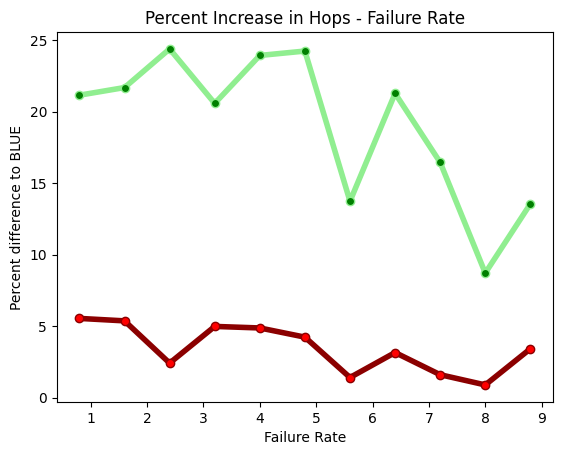

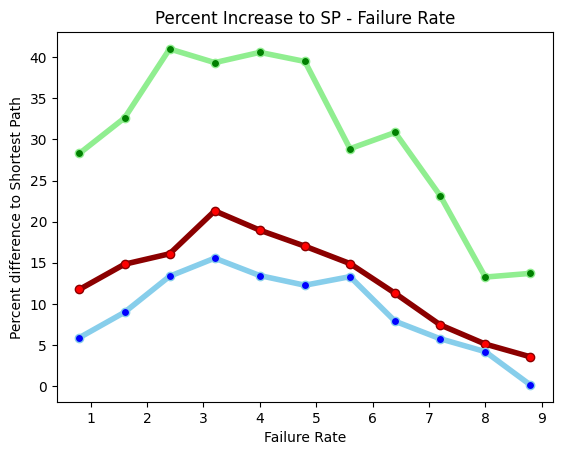

percent increase mult to edp: [1.21153846 1.21687136 1.24389499 1.20580153 1.23932975 1.24240423
 1.13732041 1.21282051 1.16452242 1.08709107 1.13547053]
percent increase one to edp: [1.05537135 1.05365223 1.02411477 1.04977099 1.04868795 1.04227213
 1.01403274 1.03150183 1.01598441 1.00884173 1.03412616]
avg increase mult to edp: 1.190642296823598
avg increase one to edp: 1.0343960279161644


In [18]:
path_base = '../../output/Paper_CSVs/n25-random/'

xVals = []
x = 0.8
while(x <= 8.8):
    xVals.append(x)
    x += 0.8
    x = round(x, 1)

files = ['trees-p0.15-n25-ff'+str(val)+'.csv' for val in xVals]


nrFiles = len(files)
rPaths = [None] * nrFiles
rOne = [None] * nrFiles
rMult = [None] * nrFiles

avgHopsPaths = [None] * nrFiles
avgHopsOne = [None] * nrFiles
avgHopsMult = [None] * nrFiles
avgHopsSP = [None] * nrFiles


for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)


plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

printHopPercent(avgHopsPaths, avgHopsOne, avgHopsMult)

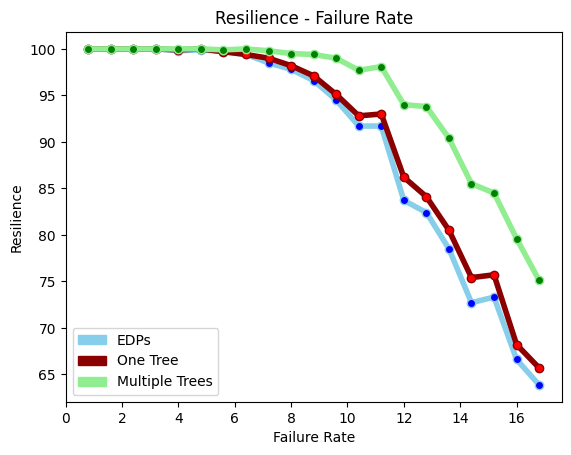

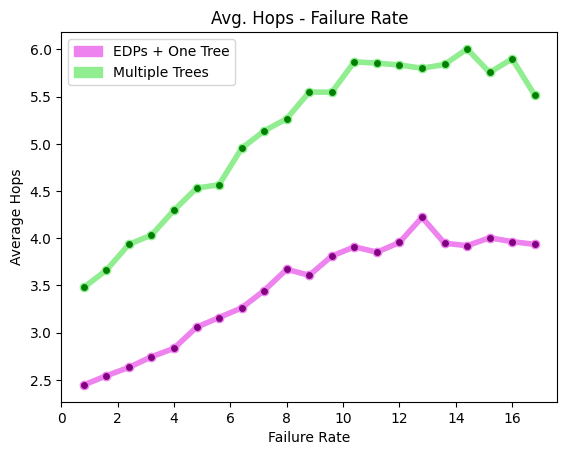

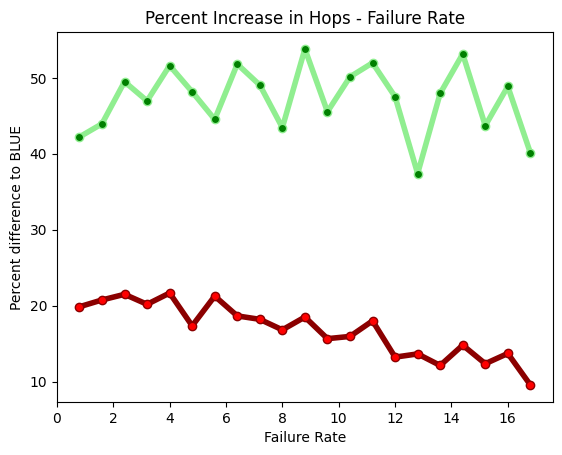

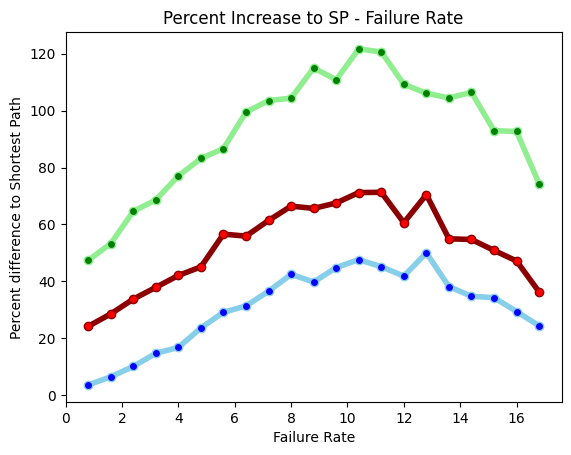

percent increase mult to edp: [1.42214957 1.43946541 1.49487277 1.46958106 1.51608342 1.48150573
 1.44525547 1.51803885 1.4904271  1.43441938 1.53802009 1.45530261
 1.50125523 1.51967167 1.47508306 1.37395803 1.47950952 1.53139249
 1.4369891  1.48863636 1.40123111]
percent increase one to edp: [1.19861054 1.20754717 1.21496392 1.20182149 1.21668434 1.17348609
 1.21263091 1.18655566 1.1820324  1.16819827 1.18507891 1.15657968
 1.1595537  1.18001698 1.13228632 1.13653349 1.12132946 1.14801824
 1.1236376  1.13712121 1.0956911 ]
avg increase mult to edp: 1.4720403827259259
avg increase one to edp: 1.1684941660502803


In [19]:
path_base = '../../output/Paper_CSVs/n50-random/'

xVals = []
x = 0.8
while(x <= 16.8):
    xVals.append(x)
    x += 0.8
    x = round(x, 1)

files = ['trees-p0.15-n50-ff'+str(val)+'.csv' for val in xVals]


nrFiles = len(files)
rPaths = [None] * nrFiles
rOne = [None] * nrFiles
rMult = [None] * nrFiles

avgHopsPaths = [None] * nrFiles
avgHopsOne = [None] * nrFiles
avgHopsMult = [None] * nrFiles
avgHopsSP = [None] * nrFiles

for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)


plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

printHopPercent(avgHopsPaths, avgHopsOne, avgHopsMult)

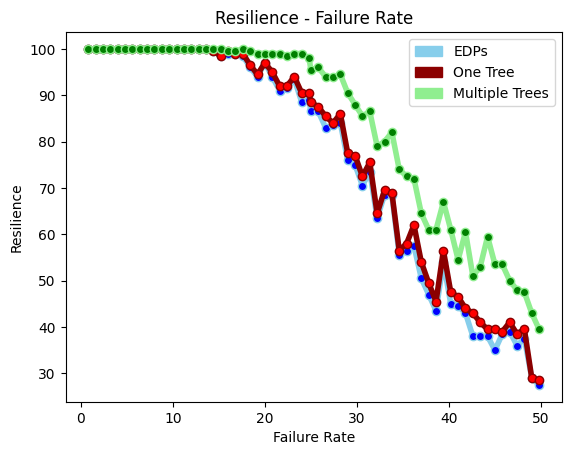

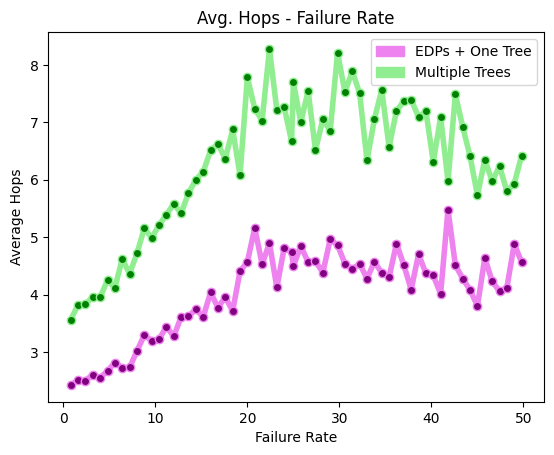

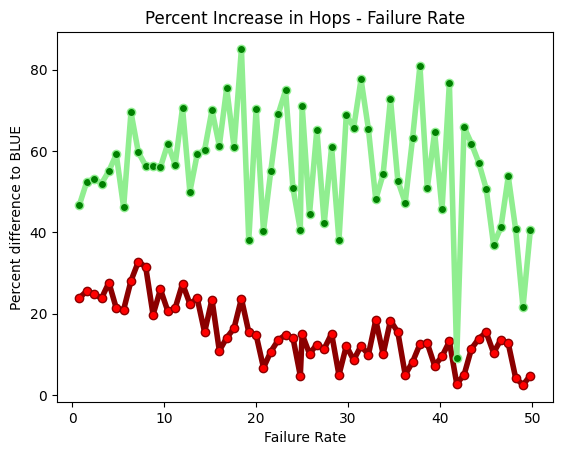

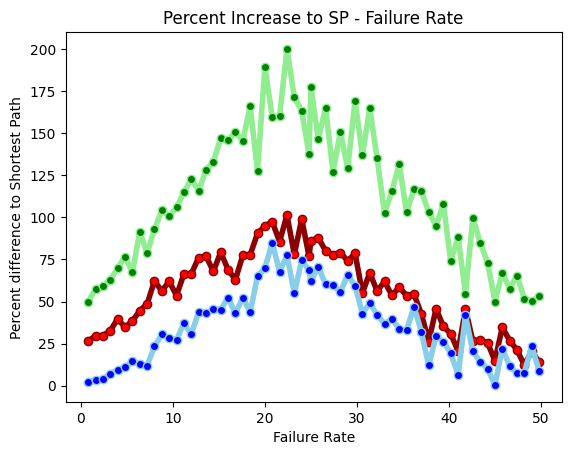

[np.float64(2.425), np.float64(2.505), np.float64(2.5), np.float64(2.605), np.float64(2.55), np.float64(2.67), np.float64(2.815), np.float64(2.725), np.float64(2.73), np.float64(3.015), np.float64(3.295), np.float64(3.195), np.float64(3.22), np.float64(3.44), np.float64(3.27), np.float64(3.61), np.float64(3.62), np.float64(3.7437185929648242), np.float64(3.6091370558375635), np.float64(4.0353535353535355), np.float64(3.772727272727273), np.float64(3.954314720812183), np.float64(3.7135416666666665), np.float64(4.404255319148936), np.float64(4.56701030927835), np.float64(5.159574468085107), np.float64(4.527472527472527), np.float64(4.896174863387978), np.float64(4.122994652406417), np.float64(4.813559322033898), np.float64(4.741573033707865), np.float64(4.497109826589595), np.float64(4.84393063583815), np.float64(4.566265060240964), np.float64(4.580838323353293), np.float64(4.380952380952381), np.float64(4.9605263157894735), np.float64(4.86), np.float64(4.539007092198582), np.float64(4.4

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

path_base = '../../output/Paper_CSVs/n100-random/'

xVals = []
x = 0.8
while(x <= 50.0):
    xVals.append(x)
    if x == 24.8:
        x+=0.2
    else:
        x += 0.8
    x = round(x, 1)

files = ['trees-p0.1-n100-ff'+str(val)+'.csv' for val in xVals]


nrFiles = len(files)
rPaths = [None] * nrFiles
rOne = [None] * nrFiles
rMult = [None] * nrFiles

avgHopsPaths = [None] * nrFiles
avgHopsOne = [None] * nrFiles
avgHopsMult = [None] * nrFiles
avgHopsSP = [None] * nrFiles


for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)


plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

print(avgHopsPaths)
print(avgHopsMult)

printHopPercent(avgHopsPaths, avgHopsOne, avgHopsMult)


In [21]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Aktueller Notebook-Arbeitsordner:")
print(os.getcwd())

path = Path("../../output/Paper_CSVs/n50-random/")

print(path.resolve())
print(path.exists())

print("Dateien im Ordner:")
for f in path.iterdir():
    print(f.name)

Aktueller Notebook-Arbeitsordner:
C:\Users\test\ba-gamous-disjoint\schritt1_reproduktion\evaluation\notebooks\resilience
C:\Users\test\ba-gamous-disjoint\schritt1_reproduktion\evaluation\output\Paper_CSVs\n50-random
True
Dateien im Ordner:
trees-p0.15-n50-ff0.8.csv
trees-p0.15-n50-ff1.6.csv
trees-p0.15-n50-ff10.4.csv
trees-p0.15-n50-ff11.2.csv
trees-p0.15-n50-ff12.0.csv
trees-p0.15-n50-ff12.8.csv
trees-p0.15-n50-ff13.6.csv
trees-p0.15-n50-ff14.4.csv
trees-p0.15-n50-ff15.2.csv
trees-p0.15-n50-ff16.0.csv
trees-p0.15-n50-ff16.8.csv
trees-p0.15-n50-ff2.4.csv
trees-p0.15-n50-ff3.2.csv
trees-p0.15-n50-ff4.0.csv
trees-p0.15-n50-ff4.8.csv
trees-p0.15-n50-ff5.6.csv
trees-p0.15-n50-ff6.4.csv
trees-p0.15-n50-ff7.2.csv
trees-p0.15-n50-ff8.0.csv
trees-p0.15-n50-ff8.8.csv
trees-p0.15-n50-ff9.6.csv


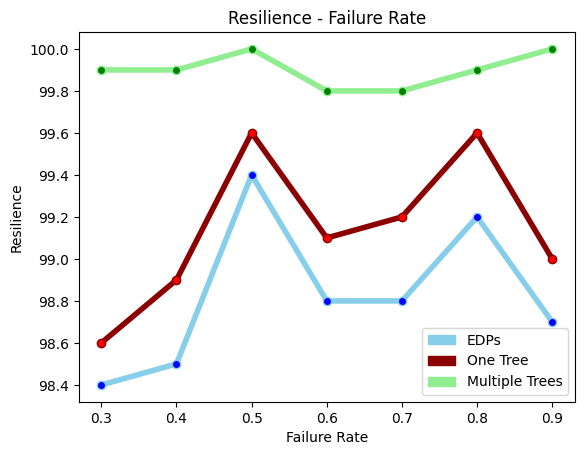

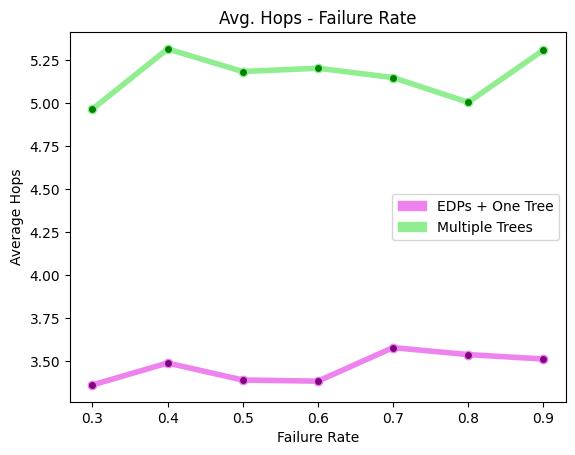

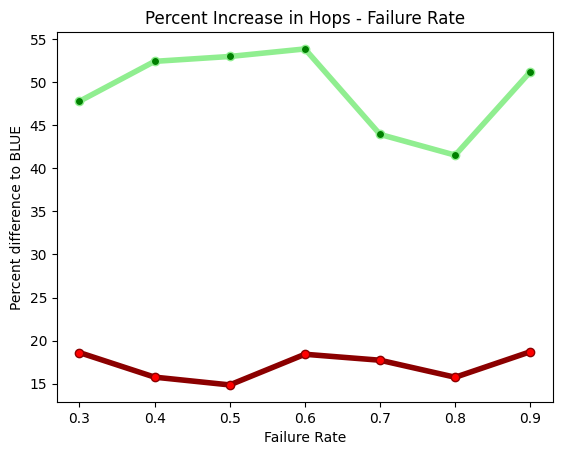

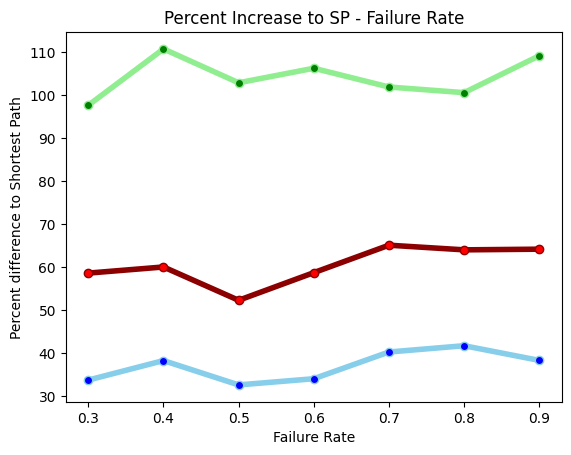

percent increase mult to edp: [1.47791894 1.52430859 1.52998812 1.53876085 1.43944539 1.41533637
 1.51226551]
percent increase one to edp: [1.18602541 1.15749636 1.14845606 1.18407662 1.17713639 1.15735462
 1.18701299]
avg increase mult to edp: 1.4911462529748696
avg increase one to edp: 1.1710797777857402


In [27]:
path_base = '../../output/Paper_CSVs/n50-random_/'
files = ['trees-p0.15-n50-f0.3.csv', 
         'trees-p0.15-n50-f0.4.csv', 
         'trees-p0.15-n50-f0.5.csv',
         'trees-p0.15-n50-f0.6.csv',
         'trees-p0.15-n50-f0.7.csv',
         'trees-p0.15-n50-f0.8.csv',
         'trees-p0.15-n50-f0.9.csv'
        ]
nrFiles = len(files)
rPaths = [None] * nrFiles
rOne = [None] * nrFiles
rMult = [None] * nrFiles

avgHopsPaths = [None] * nrFiles
avgHopsOne = [None] * nrFiles
avgHopsMult = [None] * nrFiles
avgHopsSP = [None] * nrFiles

for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)


plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

printHopPercent(avgHopsPaths, avgHopsOne, avgHopsMult)

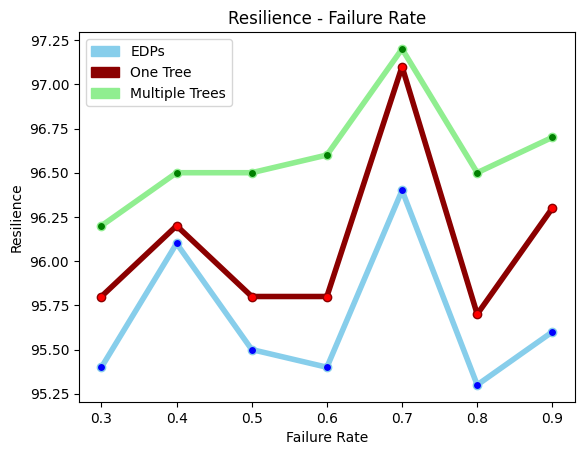

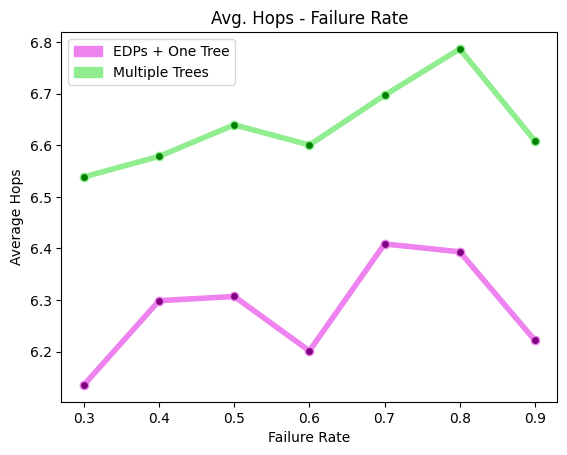

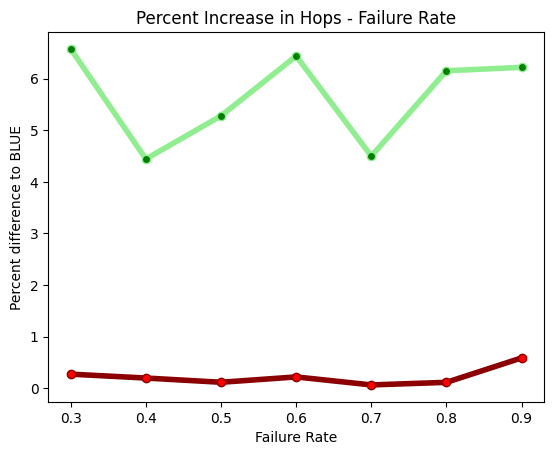

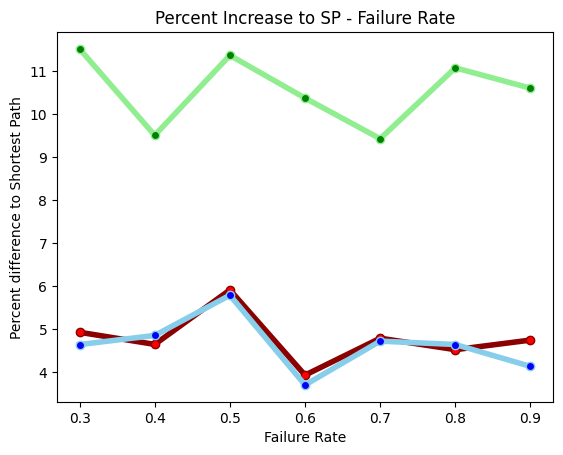

In [29]:
path_base = '../../output/Paper_CSVs/n100-random_/'
pStr = "0.02"
nStr = "100"
files = ['trees-p' + pStr + '-n' + nStr + '-f0.3.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.4.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.5.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.6.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.7.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.8.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.9.csv', 
        ]

for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

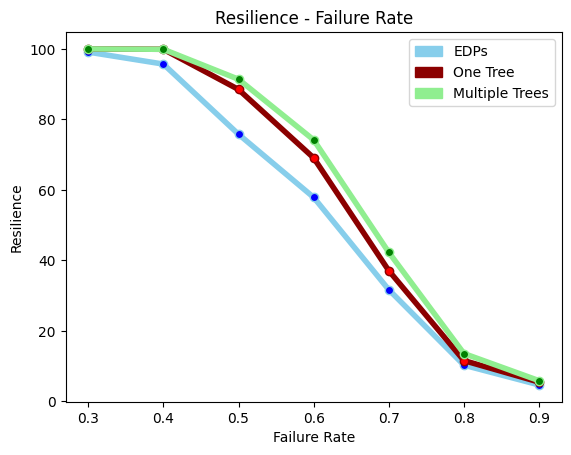

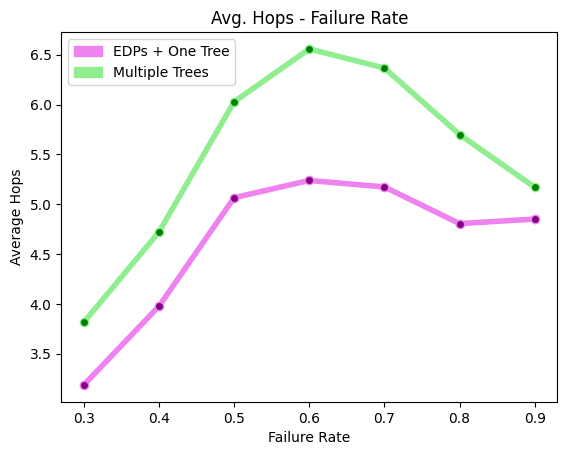

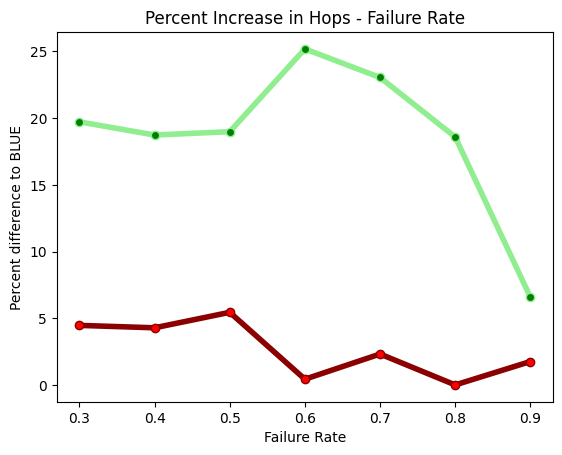

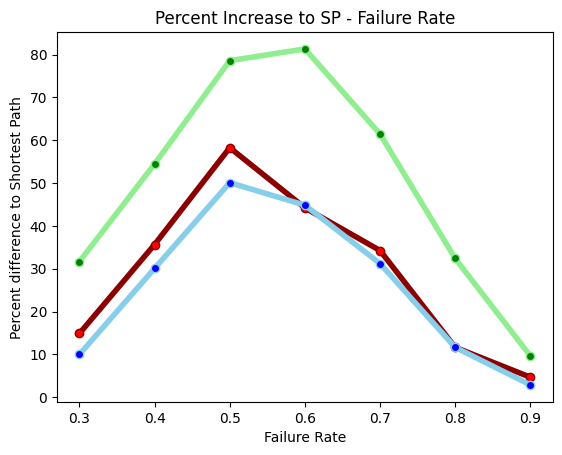

In [30]:
path_base = '../../output/Paper_CSVs/n25-clustered/'
pStr = "0.15"
nStr = "25"
files = ['trees-p' + pStr + '-n' + nStr + '-f0.3.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.4.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.5.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.6.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.7.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.8.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.9.csv', 
        ]

for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

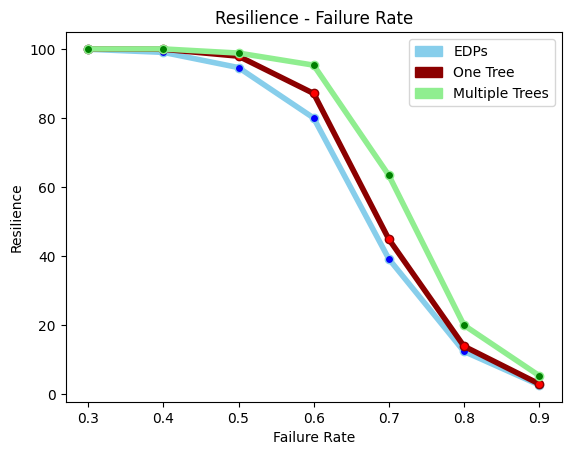

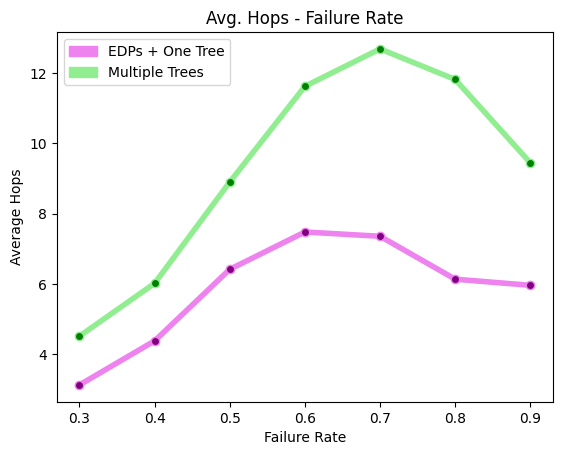

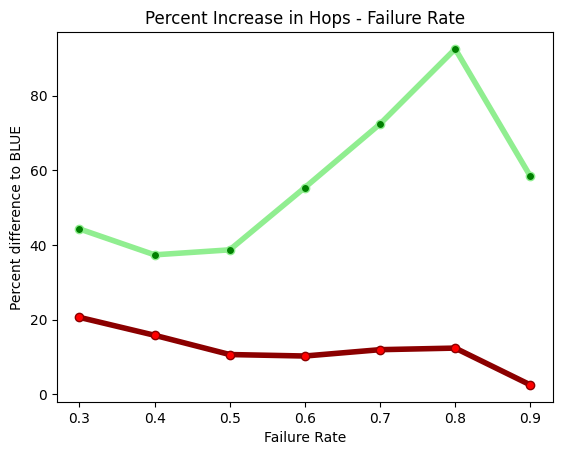

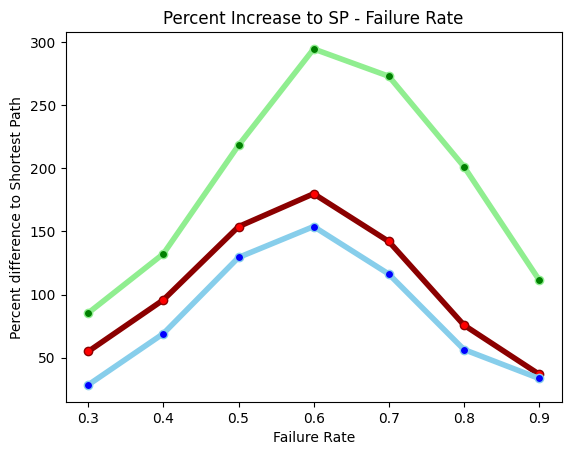

In [31]:
path_base = '../../output/Paper_CSVs/n50-clustered/'
pStr = "0.15"
nStr = "50"
files = ['trees-p' + pStr + '-n' + nStr + '-f0.3.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.4.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.5.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.6.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.7.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.8.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.9.csv', 
        ]

for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

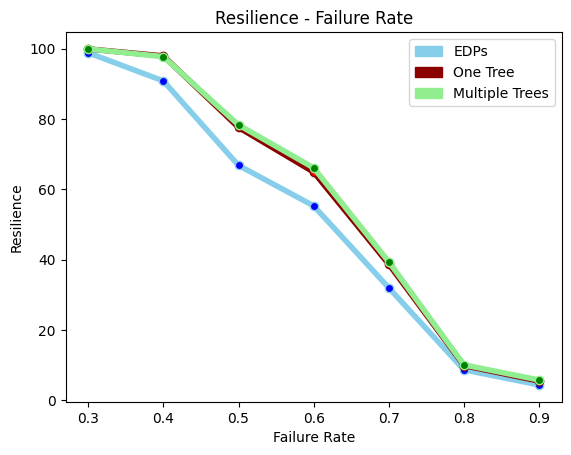

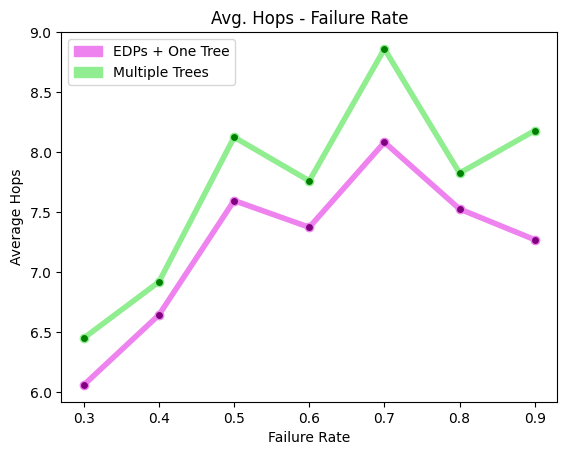

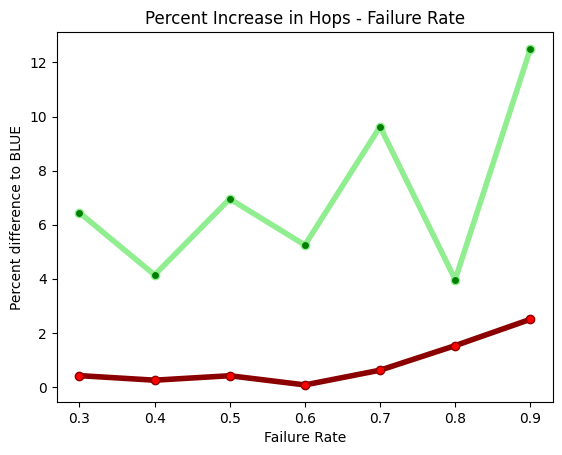

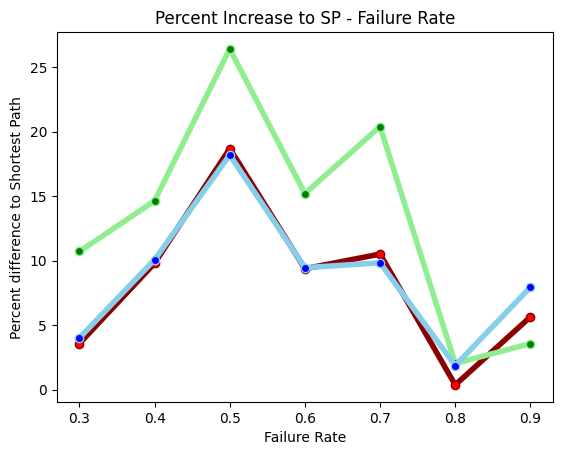

In [32]:
path_base = '../../output/Paper_CSVs/n100-clustered/'
pStr = "0.02"
nStr = "100"
files = ['trees-p' + pStr + '-n' + nStr + '-f0.3.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.4.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.5.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.6.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.7.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.8.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.9.csv', 
        ]


for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 3, figsize=(10,5))

#fig.suptitle('Experiment Results for Clustered Failures (1000 runs)', fontsize=16)


plt.subplots_adjust(left=0.1,
                    bottom=0.1, 
                    right=1, 
                    top=0.9, 
                    wspace=0.15, 
                    hspace=0.25)
fontsize1 = 14
fontsize2 = 20
fontsize3 = 14

ax1[0].set_title('Rnd. Graph (n=25, p=0.15)', fontsize=fontsize1, fontweight='bold')
ax1[0].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
ax1[0].set_ylabel('Resilience', fontsize=fontsize2)

ax1[1].set_title('Rnd. Graph (n=50, p=0.15)', fontsize=fontsize1, fontweight='bold')
ax1[1].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax1[1].set_ylabel('Resilience')

ax1[2].set_title('Rnd. Graph (n=100, p=0.02)', fontsize=fontsize1, fontweight='bold')
ax1[2].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax1[2].set_ylabel('Resilience')


#ax2[0].set_title('Random Graph (n=25, p=0.15)')
ax2[0].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
ax2[0].set_ylabel('Avg. Hops', fontsize=fontsize2)

#ax2[1].set_title('Random Graph (n=50, p=0.15)')
ax2[1].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax2[1].set_ylabel('Avg. Hops Needed')

#ax2[2].set_title('Random Graph (n=100, p=0.02)')
ax2[2].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax2[2].set_ylabel('Avg. Hops Needed')

#------------------------------------------------------------------------------------

path_base = '../../output/Paper_CSVs/n25-clustered/'
pStr = "0.15"
nStr = "25"
files = ['trees-p' + pStr + '-n' + nStr + '-f0.3.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.4.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.5.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.6.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.7.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.8.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.9.csv', 
        ]

rPaths = [None] * len(files)
rOne = [None] * len(files)
rMult = [None] * len(files)

avgHopsPaths = [None] * len(files)
avgHopsOne = [None] * len(files)
avgHopsMult = [None] * len(files)
avgHopsSP = [None] * len(files)

for i in range(len(files)):
    
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
xVals = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
plotEvalAx2(xVals, (ax1, ax2, 0), rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, markersize=3, alpha=1) 

n25resDiffMult = np.max(np.array(rMult) - np.array(rPaths))
n25resDiffOne = np.max(np.array(rOne) - np.array(rPaths))
n25hopIncrease = np.mean(np.array(avgHopsMult) - np.array(avgHopsPaths))


#------------------------------------------------------------------------------------


path_base = '../../output/Paper_CSVs/n50-clustered/'
pStr = "0.15"
nStr = "50"
files = ['trees-p' + pStr + '-n' + nStr + '-f0.3.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.4.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.5.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.6.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.7.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.8.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.9.csv', 
        ]


for i in range(len(files)):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEvalAx2(xVals, (ax1, ax2, 1), rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, markersize=3, alpha=1) 

n50resDiffMult = np.max(np.array(rMult) - np.array(rPaths))
n50resDiffOne = np.max(np.array(rOne) - np.array(rPaths))
n50hopIncrease = np.mean(np.array(avgHopsMult) - np.array(avgHopsPaths))

#------------------------------------------------------------------------------------



path_base = '../../output/Paper_CSVs/n100-clustered/'
pStr = "0.02"
nStr = "100"
files = ['trees-p' + pStr + '-n' + nStr + '-f0.3.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.4.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.5.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.6.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.7.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.8.csv', 
         'trees-p' + pStr + '-n' + nStr + '-f0.9.csv', 
        ]


for i in range(len(files)):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEvalAx2(xVals, (ax1, ax2, 2), rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, markersize=3, alpha=1) 

n100resDiffMult = np.max(np.array(rMult) - np.array(rPaths))
n100resDiffOne = np.max(np.array(rOne) - np.array(rPaths))
n100hopIncrease = np.mean(np.array(avgHopsMult) - np.array(avgHopsPaths))


print("max res diff mult:", np.max([n25resDiffMult, n50resDiffMult, n100resDiffMult]))
print("max res diff one:", np.max([n25resDiffOne, n50resDiffOne, n100resDiffOne]))
print("mean increase:", np.mean([n25hopIncrease, n50hopIncrease, n100hopIncrease]))

fig.savefig('subplots_random_clustered_.png', bbox_inches="tight")
fig.savefig('subplots_random_clustered_.svg', bbox_inches="tight")

In [ ]:
#RANDOM FIX
fig, (ax1, ax2) = plt.subplots(2, 3, figsize=(10,5))

#fig.suptitle('Experiment Results for Clustered Failures (1000 runs)', fontsize=16)

plt.subplots_adjust(left=0.1,
                    bottom=0.1, 
                    right=1, 
                    top=0.9, 
                    wspace=0.15, 
                    hspace=0.25)

fontsize1 = 14
fontsize2 = 20
fontsize3 = 14

ax1[0].set_title('Rnd. Graph (n=25, p=0.15)', fontsize=fontsize1, fontweight='bold')
ax1[0].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
ax1[0].set_ylabel('Resilience', fontsize=fontsize2)

ax1[1].set_title('Rnd. Graph (n=50, p=0.15)', fontsize=fontsize1, fontweight='bold')
ax1[1].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax1[1].set_ylabel('Resilience')

ax1[2].set_title('Rnd. Graph (n=100, p=0.02)', fontsize=fontsize1, fontweight='bold')
ax1[2].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax1[2].set_ylabel('Resilience')


#ax2[0].set_title('Random Graph (n=25, p=0.15)')
ax2[0].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
ax2[0].set_ylabel('Avg. Hops', fontsize=fontsize2)

#ax2[1].set_title('Random Graph (n=50, p=0.15)')
ax2[1].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax2[1].set_ylabel('Avg. Hops Needed')

#ax2[2].set_title('Random Graph (n=100, p=0.02)')
ax2[2].set_xlabel('Failure Rate',labelpad=-1, fontsize=fontsize3)
#ax2[2].set_ylabel('Avg. Hops Needed')

#------------------------------------------------------------------------------------

path_base = '../../output/Paper_CSVs/n25-random/'

xVals = []
x = 0.8
while(x <= 8.8):
    xVals.append(x)
    x += 0.8
    x = round(x, 1)

files = ['trees-p0.15-n25-ff'+str(val)+'.csv' for val in xVals]

nrFiles = len(files)
rPaths = [None] * nrFiles
rOne = [None] * nrFiles
rMult = [None] * nrFiles

avgHopsPaths = [None] * nrFiles
avgHopsOne = [None] * nrFiles
avgHopsMult = [None] * nrFiles
avgHopsSP = [None] * nrFiles
for i in range(nrFiles):
    
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEvalAx2(xVals, (ax1, ax2, 0), rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

n25resDiffMult = np.max(np.array(rMult) - np.array(rPaths))
n25resDiffOne = np.max(np.array(rOne) - np.array(rPaths))
n25hopIncrease = np.mean(np.array(avgHopsMult) - np.array(avgHopsPaths))
#------------------------------------------------------------------------------------


path_base = '../../output/Paper_CSVs/n50-random/'

xVals = []
x = 0.8
while(x <= 16.8):
    xVals.append(x)
    x += 0.8
    x = round(x, 1)

files = ['trees-p0.15-n50-ff'+str(val)+'.csv' for val in xVals]

nrFiles = len(files)
rPaths = [None] * nrFiles
rOne = [None] * nrFiles
rMult = [None] * nrFiles

avgHopsPaths = [None] * nrFiles
avgHopsOne = [None] * nrFiles
avgHopsMult = [None] * nrFiles
avgHopsSP = [None] * nrFiles
for i in range(nrFiles):
    
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)
    
plotEvalAx2(xVals, (ax1, ax2, 1), rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

n50resDiffMult = np.max(np.array(rMult) - np.array(rPaths))
n50resDiffOne = np.max(np.array(rOne) - np.array(rPaths))
n50hopIncrease = np.mean(np.array(avgHopsMult) - np.array(avgHopsPaths))

#------------------------------------------------------------------------------------


path_base = '../../output/Paper_CSVs/n100-random/'

xVals = []
x = 0.8
while(x <= 50.0):
    xVals.append(x)
    if x == 24.8:
        x+=0.2
    else:
        x += 0.8
    x = round(x, 1)

files = ['trees-p0.1-n100-ff'+str(val)+'.csv' for val in xVals]


nrFiles = len(files)
rPaths = [None] * nrFiles
rOne = [None] * nrFiles
rMult = [None] * nrFiles

avgHopsPaths = [None] * nrFiles
avgHopsOne = [None] * nrFiles
avgHopsMult = [None] * nrFiles
avgHopsSP = [None] * nrFiles


for i in range(nrFiles):
    allInOne(path_base + files[i], i, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, printRes=False)

    
plotEvalAx2(xVals, (ax1, ax2, 2), rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP) 

n100resDiffMult = np.max(np.array(rMult) - np.array(rPaths))
n100resDiffOne = np.max(np.array(rOne) - np.array(rPaths))
n100hopIncrease = np.mean(np.array(avgHopsMult) - np.array(avgHopsPaths))


print("max res diff mult:", np.max([n25resDiffMult, n50resDiffMult, n100resDiffMult]))
print("max res diff one:", np.max([n25resDiffOne, n50resDiffOne, n100resDiffOne]))
print("mean increase:", np.mean([n25hopIncrease, n50hopIncrease, n100hopIncrease]))


fig.savefig('subplots_random_random_.png', bbox_inches="tight")
fig.savefig('subplots_random_random_.svg', bbox_inches="tight")

In [ ]:
#do relative drop-off!